# PolicyLens Dataset Audit and Conservative Cleaning

This notebook audits the three Open Government consultation datasets already present in the project. It is designed for a B.Tech CSE (AI) research workflow: every result is calculated from local files, raw inputs are preserved unchanged, and cleaned outputs are kept separate from source data.

**Important boundaries:** this notebook does not train models, does not download data, does not merge datasets, and does not invent sentiment/stance/concern labels.

## 1. Setup

We import only standard scientific Python tools available in the environment. Paths are resolved relative to the project root so the notebook can be rerun from VS Code without hardcoded machine-specific absolute paths.

In [1]:
import csv
import hashlib
import json
import re
from collections import Counter
from dataclasses import dataclass
from difflib import SequenceMatcher
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (10, 4)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_INTERIM = PROJECT_ROOT / "data" / "interim"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
NOTEBOOKS_DIR = PROJECT_ROOT / "notebooks"

for directory in [DATA_INTERIM, DATA_PROCESSED, REPORTS_DIR, NOTEBOOKS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

PROJECT_ROOT

WindowsPath('C:/Users/MAYANK SWAROOP/OneDrive/Desktop/dataset')

## Helper Functions

These functions keep the notebook readable. They detect encodings and delimiters, normalize only whitespace/empty values, redact obvious contact details in displayed samples, and preserve traceability through source row numbers.

In [2]:
@dataclass(frozen=True)
class ConsultationDataset:
    key: str
    title: str
    path: Path
    header_rows: int
    data_header_row: int


def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def sniff_encoding(path: Path) -> str:
    raw = path.read_bytes()
    scores = []
    for encoding in ["utf-8-sig", "utf-8", "cp1252", "latin-1"]:
        try:
            text = raw.decode(encoding)
        except UnicodeDecodeError:
            continue
        replacement_chars = text.count("\ufffd")
        mojibake_markers = text.count("Ã") + text.count("Â")
        scores.append((replacement_chars * 100 + mojibake_markers, encoding))
    return sorted(scores)[0][1] if scores else "latin-1"


def sniff_delimiter(path: Path, encoding: str) -> str:
    sample = path.read_text(encoding=encoding, errors="replace")[:50_000]
    return csv.Sniffer().sniff(sample, delimiters=",;\t|").delimiter


def clean_cell(value):
    if value is None or pd.isna(value):
        return None
    text = str(value).replace("\r\n", "\n").replace("\r", "\n")
    text = re.sub(r"[ \t\f\v]+", " ", text)
    text = re.sub(r" *\n *", "\n", text).strip()
    if text in {"", "nan", "NaN", "N/A", "n/a", "NA", "nil", "Nil", "None"}:
        return None
    return text


def normalized_text_key(value):
    text = clean_cell(value)
    if text is None:
        return None
    return re.sub(r"\s+", " ", text.casefold()).strip()


def redact_text(value, limit=500):
    text = clean_cell(value)
    if text is None:
        return None
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b", "[EMAIL]", text)
    text = re.sub(r"\b(?:\+?\d[\d .()/-]{7,}\d)\b", "[PHONE_OR_ID]", text)
    return text[:limit]


def slugify_column(name: str, seen: Counter) -> str:
    text = clean_cell(name) or "unnamed"
    text = text.replace("’", "'")
    text = re.sub(r"[^0-9A-Za-z]+", "_", text).strip("_").lower()
    text = re.sub(r"_+", "_", text) or "unnamed"
    seen[text] += 1
    return text if seen[text] == 1 else f"{text}_{seen[text]}"

## 2. Dataset Loading

The files are located by searching the workspace and excluding generated folders such as `data/`, `reports/`, and cache directories. The questionnaire has two header rows; the English row is used for working column names while both header rows are preserved.

In [3]:
def locate_consultation_files(root: Path) -> list[ConsultationDataset]:
    ignored_parts = {".pytest_cache", "data", "reports", "__pycache__", "notebooks"}
    csv_files = [
        path for path in root.rglob("*.csv")
        if not (set(part.lower() for part in path.relative_to(root).parts) & ignored_parts)
    ]
    found = {}
    for path in csv_files:
        lower_name = path.name.lower()
        if "get involved questionnaire" in lower_name:
            found["get_involved_questionnaire_2017_18"] = path
        elif "individual_comments" in lower_name or "individual comments" in lower_name:
            found["individual_comments_2016_18"] = path
        elif "consultationdata2017engagement" in lower_name or "compilation" in lower_name:
            found["consultation_compilation_2017_18"] = path

    expected = {
        "get_involved_questionnaire_2017_18": ("Open Government Consultation Data 2017-18 - Get Involved Questionnaire", 2, 1),
        "individual_comments_2016_18": ("Open Government Consultation Data 2016-18 - Individual Comments", 1, 0),
        "consultation_compilation_2017_18": ("Open Government Consultation Data 2017-18 - Consultation Compilation", 1, 0),
    }
    missing = sorted(set(expected) - set(found))
    if missing:
        raise FileNotFoundError(f"Missing expected consultation dataset(s): {missing}")
    return [
        ConsultationDataset(key=key, title=expected[key][0], path=found[key], header_rows=expected[key][1], data_header_row=expected[key][2])
        for key in expected
    ]


datasets = locate_consultation_files(PROJECT_ROOT)
pd.DataFrame([
    {
        "dataset": item.key,
        "relative_path": item.path.relative_to(PROJECT_ROOT).as_posix(),
        "size_bytes": item.path.stat().st_size,
        "header_rows": item.header_rows,
    }
    for item in datasets
])

,dataset,relative_path,size_bytes,header_rows
0,get_involved_questionnaire_2017_18,Open Government Consultation Data 2017-18 Get Involved Questionnaire.csv,3048593,2
1,individual_comments_2016_18,ap2016-18_individual_comments.csv,68438,1
2,consultation_compilation_2017_18,ConsultationData2017Engagement_Donnéesdesconsultations2017engagements.csv,2982201,1


In [4]:
def raw_csv_stats(path: Path, encoding: str, delimiter: str, expected_columns: int) -> dict:
    widths = Counter()
    blank_rows = 0
    with path.open("r", encoding=encoding, errors="replace", newline="") as file:
        reader = csv.reader(file, delimiter=delimiter)
        for row in reader:
            widths[len(row)] += 1
            if not any(clean_cell(cell) for cell in row):
                blank_rows += 1
    malformed_records = sum(count for width, count in widths.items() if width != expected_columns)
    return {
        "blank_rows": blank_rows,
        "malformed_records": malformed_records,
        "row_width_distribution": dict(sorted(widths.items())),
    }


def load_consultation_dataset(spec: ConsultationDataset, encoding: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    raw = pd.read_csv(spec.path, encoding=encoding, header=None, dtype="string", keep_default_na=False)
    header_rows = raw.iloc[: spec.header_rows].copy()
    data = raw.iloc[spec.header_rows :].copy()
    seen = Counter()
    columns = []
    for index, value in enumerate(raw.iloc[spec.data_header_row]):
        original = clean_cell(value) or f"unnamed_{index + 1}"
        seen[original] += 1
        columns.append(original if seen[original] == 1 else f"{original}__duplicate_{seen[original]}")
    data.columns = columns
    data = data.reset_index(drop=True).map(clean_cell)
    return data, header_rows


loaded_data = {}
header_rows_by_dataset = {}
file_metadata = []
raw_checksums_before = {}

for spec in datasets:
    encoding = sniff_encoding(spec.path)
    delimiter = sniff_delimiter(spec.path, encoding)
    data_frame, header_rows = load_consultation_dataset(spec, encoding)
    raw_stats = raw_csv_stats(spec.path, encoding, delimiter, data_frame.shape[1])
    checksum = sha256(spec.path)
    raw_checksums_before[spec.key] = checksum
    loaded_data[spec.key] = data_frame
    header_rows_by_dataset[spec.key] = header_rows
    file_metadata.append({
        "dataset_name": spec.key,
        "dataset_title": spec.title,
        "relative_path": spec.path.relative_to(PROJECT_ROOT).as_posix(),
        "file_size_bytes": spec.path.stat().st_size,
        "encoding": encoding,
        "delimiter": delimiter,
        "header_structure": f"{spec.header_rows} header row(s); data column names from row {spec.data_header_row + 1}",
        "sha256": checksum,
        "blank_rows": raw_stats["blank_rows"],
        "malformed_records": raw_stats["malformed_records"],
        "row_width_distribution": json.dumps(raw_stats["row_width_distribution"], ensure_ascii=False),
    })

file_metadata_df = pd.DataFrame(file_metadata)
file_metadata_df

,dataset_name,dataset_title,relative_path,file_size_bytes,encoding,delimiter,header_structure,sha256,blank_rows,malformed_records,row_width_distribution
0,get_involved_questionnaire_2017_18,Open Government Consultation Data 2017-18 - Get Involved Questionnaire,Open Government Consultation Data 2017-18 Get Involved Questionnaire.csv,3048593,cp1252,",",2 header row(s); data column names from row 2,bebcc9e5264fc00788c4094b579f90dcf2f8590aaeab528f30a338a7e2344239,0,0,"{""98"": 8214}"
1,individual_comments_2016_18,Open Government Consultation Data 2016-18 - Individual Comments,ap2016-18_individual_comments.csv,68438,cp1252,",",1 header row(s); data column names from row 1,f67c2a923fa9d47c969adc4a9a271fab3fd746752875714f176d5ce920238457,14,0,"{""19"": 161}"
2,consultation_compilation_2017_18,Open Government Consultation Data 2017-18 - Consultation Compilation,ConsultationData2017Engagement_Donnéesdesconsultations2017engagements.csv,2982201,cp1252,",",1 header row(s); data column names from row 1,3067c1ee5500a899ab7c3727e55af89a23e782375b81a4abbc54e5537333e4bc,0,0,"{""63"": 5170}"


In [5]:
for spec in datasets:
    print(f"\n{spec.title}")
    display(loaded_data[spec.key].head(3))
    display(pd.DataFrame({
        "column_name": loaded_data[spec.key].columns,
        "dtype": loaded_data[spec.key].dtypes.astype(str).values,
        "missing": loaded_data[spec.key].isna().sum().values,
    }).head(25))


Open Government Consultation Data 2017-18 - Get Involved Questionnaire


,Unique Identifier,Language,Start Date,End Date,Q1. Is transparency an important issue for you?,Q2. What are your three most important government transparency topics?,Q2R. Being able to find the person in government I need to talk to.,Q2R. Learning about government policies and programs.,Q2R. Being able to request and get documents about government operations or decisions easily.,Q2R. Learning about the work of government officials.,Q2R. Being able to find out about government spending.,"Q2R. As much as possible, having access to the same data as government.",Q2R. Viewing information on everyday government business like spending on hospitality or job reclassifications (also known as Proactive Disclosure).,"Q2R. The Canadian Government working with other governments (state, municipal, provincial, territorial or international) to help them be more open.",Q2R. Other (please specify),Q3. Is government accountability an important issue for you?,Q4. What are your three most important government accountability needs?,Q4R. Keeping an eye on government spending and potential conflicts of interest.,Q4R. Understanding who seeks to influence government decision making (e.g. through lobbying).,Q4R. Having the information available to hold government accountable.,Q4R. Being able to track progress on government’s commitments.,Q4R. Strengthening privacy and data protection for Canadians.,Q4R. Other (please specify)6,Q5. Is citizen participation in government an important issue for you,Q6. What are the three most important ways to participate and interact with government?,Q6R. Being given an opportunity to provide my views and concerns to government.,Q6R. Being able to provide input into government decision making.,Q6R. Being able to interact with other Canadians on issues of shared concern.,Q6R. Being able to collaborate directly with government on issues I care about.,Q6R. Simplifying my interaction with government by allowing government departments to share my information with each other.,Q6R. Being able to make suggestions on improving government services.,Q6R. Being able to track the status of my data/information request or suggestion.,Q6R. Other (please specify),Q7. The federal government works to improve the 16 strategic outcomes listed below. What are the three most important outcomes to be included in Canada’s 4th Plan on Open Government?,Q7R. Income security and employment,Q7R. Economic growth,Q7R. Innovation and knowledge based economy,Q7R. Clean and healthy environment,Q7R. Fair and secure workplace,Q7R. Healthy Canadians,...,Q9R. I am looking for opportunities to make society better,Q9R. I support open government as a tool to make democracy stronger,Q9R. I provide feedback to the government only when I am asked about an issue I care about,Q9R. I am looking for opportunities to hold government accountable,Q9R. I build collections of data and information around a particular topic,Q9R. I am not that interested in open government actually,Q9R. I prefer not to answer this question,Q9R. Other (please specify)9,Q10. Would you like to be more involved in developing Canada’s 4th Plan on Open Government,Q11. What would you like to be involved in? Check all that apply.,Q11R. I would like to share my knowledge,Q11R. I would like to give you feedback on draft documents,Q11R. I would like to help you organize or run an engagement workshop on open government,Q11R. I would like to promote events for developing Canada’s 4th Plan on Open Government within my network,Q11R. I would like to attend a workshop,Q11R. Other: I can..,Q12. How would you like to be involved? Check all that apply.,Q12R. open.canada.ca,Q12R. Facebook,Q12R. Twitter,Q12R. LinkedIn,Q12R. Reddit,Q12R. Webinars,Q12R. Github,Q12R. Google Docs,Q12R. GCcollab,Q12R. Questionnaires like this one,Q12R. In person: Small groups,Q12R. In person: Larger groups,Q12R. Other (please specify),Q13. Please indicate your satisfaction with the current open government data and information services on

,column_name,dtype,missing
0,Unique Identifier,str,0
1,Language,str,0
2,Start Date,str,0
3,End Date,str,0
4,Q1. Is transparency an important issue for you?,str,1
5,Q2. What are your three most important government transparency topics?,object,8212
6,Q2R. Being able to find the person in government I need to talk to.,str,4813
7,Q2R. Learning about government policies and programs.,str,4964
8,Q2R. Being able to request and get documents about government operations or decisions easily.,str,4496
9,Q2R. Learning about the work of government officials.,str,6989



Open Government Consultation Data 2016-18 - Individual Comments


,Row\nRangée,Event,Événement,Source,Source__duplicate_2,Source Language,Langue de départ,Sector,Secteur,Public Engagement Question (Also in Compilation)\nQuestion sur la mobilisation du,1 Practical idea (Also in Compilation)\nUne idée pratique (Toujours dans Compilation),3 words\n3 mots,OG is important because\nIl est important d’avoir un gouvernement ouvert parce que,Preferred way(s) to participate in Open Government\nFaçons préférées de participer au Gouvernement ouvert,What did you like most?\nCe que vous avez le plus aimé ?,Dislike?\nCe que vous avez moins aimé ?,Improvements?\nAméliorations,Would you recommend?\nRecommanderiez-vous,Other comments\nAutres commentaires
0,35,ARMA 2016,ARMA 2016,Indv Comment,Commentaire individuel,English,Anglais,Academia,Milieu universitaire,Monitoring of open government initiatives for improvement in government performance - concrete connections.,Describe benefits and intentions clearly. Tie it to cost savings / service improvements.,"open, data, explanation",I need to understand what this intiative means to accomplish,"4, 6",table discussions,the presentation was too long and too vague,NaN,8,NaN
1,91,Montreal 2016,Montréal 2016,Indv Comment,Commentaire individuel,English,Anglais,Academia,Milieu universitaire,NaN,NaN,"m'informer, recontrer les gens",Je m’intéresse aux contextes de développement des données ouvertes et du web sémantique. RT: I am interested in the production of open d...,"4,6",L’échange d’information et la rencontre de certaines personnes. RT: The exchange of information and the meeting/ coming together of cert...,NaN,NaN,10,NaN
2,101,Ottawa 2016,Ottawa 2016,Indv Comment,Commentaire individuel,English,Anglais,Academia,Milieu universitaire,NaN,Data I want button on each department website with voting-- get at questions lots of people ask.,"Learn, share, network.",The potential for democracy!,"1,2,3,4,5,6",Discussion/ instructions.,NaN,NaN,10,NaN


,column_name,dtype,missing
0,Row\nRangée,str,14
1,Event,str,14
2,Événement,str,14
3,Source,str,14
4,Source__duplicate_2,str,14
5,Source Language,str,14
6,Langue de départ,str,14
7,Sector,str,18
8,Secteur,str,20
9,Public Engagement Question (Also in Compilation)\nQuestion sur la mobilisation du,str,48



Open Government Consultation Data 2017-18 - Consultation Compilation


,ID,Row/Ligne,Event\nÉvénement,Événement\nEvent (FR),Source,Source (FR),Context/Prompt\nContexte/Message-guide,Contexte/Message-guide\nContext/Prompt Traduction si disponible,Subject\nObjet,Subject translation if available\nTraduction objet si disponible,Comment and Subject Translation Required?,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",Votes,"Comment, Question or Idea translation if available\nTraduction commentaire, question ou idée si disponible",Quotable\nCitable,Theme\nThème,Thème\nTheme (FR),Sub-theme\nSous-thème,Sous-thème\nSub-theme (FR),Working Commitment\nEngagement de travail,Engagement de travail\nWorking Commitment (FR),A1\nR1,A2\nR 1,A3\nR1,A4\nR1,A5\nR1,A6\nR1,A6\nR12,R1_Rank1,R1_Score1 (%),R1\nFinal,A1\nR 2,A2\nR2,A3\nR2,A4\nR2,A5\nR2,A6\nR2,A7\nR2,R2_Rank1,R2_Score1 (%),R2 Final,RF,Theme\nMode\nMode Thème,Sub-theme mode\nmode Sous-thème,A1 Theme\nThème A1,A2 Theme\nThème A2,A3 Theme\nThème A3,A4 Theme\nThème A4,A5 theme\nThème A5,A6\nTheme\nThème A6,Theme Count\nNombre de thèmes,Theme_Rank1,Theme_Rank1 (FR),Theme_Score1 (%),A1 Sub-theme\nSous-thème A1,A2 Sub-theme\nSous-thème A2,A3 Sub-theme\nSous-thème A3,A4 sub-theme\nSous-thème A4,A5 sub-theme\nSous-thème A5,A6 sub-theme\nSous-thème A6,Sub-theme Count\nNombre de sous-thèmes,Source Language,Langue
0,0.174006533,4252,Fredericton,Fredericton,Facilitator Notes,Notes de l’animateur,Challenges,Défis,NaN,NaN,Yes,Who makes the decision?,NaN,Qui en est responsable?,1,Culture of Openness,Culture d’ouverture,Alt - Governance & Licence,Alt – Gouvernance et licence,Digital government,Ressources de soutien sécuritaires,NaN,NaN,NaN,0,1,NaN,NaN,[1],58.62,1,NaN,NaN,NaN,0,1,NaN,NaN,[1],61.01,1,2,10,#N/A,10,NaN,NaN,10,NaN,10,3,open dialogue,Dialogue ouvert,63.51,43,NaN,NaN,NaN,NaN,20,2,English,Anglais
1,0.307433145,4251,Fredericton,Fredericton,Facilitator Notes,Notes de l’animateur,Challenges,Défis,NaN,NaN,Yes,Official languages,NaN,Les langues officielles,NaN,Open Information,Information accessible,Alt - Official Languages,Alt – Langues officielles,Other,Autre,NaN,NaN,NaN,NaN,1,NaN,NaN,[0],56.74,1,NaN,NaN,NaN,NaN,1,NaN,NaN,[0],52.52,1,2,3,38,3,NaN,3,8,NaN,NaN,3,open dialogue,Dialogue ouvert,53.41,38,NaN,38,NaN,NaN,NaN,2,English,Anglais
2,0.508799594,4253,Fredericton,Fredericton,Facilitator Notes,Notes de l’animateur,Challenges,Défis,NaN,NaN,Yes,"Official languages, accessible, Alex is exploring those issues, people are looking",NaN,Alex s’occupe de l’enjeu de l’accessibilité et des langues officielles. Les gens regardent.,NaN,Open Information,Information accessible,Alt - Official Languages,Alt – Langues officielles,Other,Autre,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[1],53.24,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[0],54.79,1,2,#N/A,38,3,NaN,NaN,12,15,NaN,3,open dialogue,Dialogue ouvert,65.26,38,NaN,NaN,38,46,NaN,3,English,Anglais


,column_name,dtype,missing
0,ID,str,0
1,Row/Ligne,str,0
2,Event\nÉvénement,str,0
3,Événement\nEvent (FR),str,0
4,Source,str,0
5,Source (FR),str,0
6,Context/Prompt\nContexte/Message-guide,str,0
7,Contexte/Message-guide\nContext/Prompt Traduction si disponible,str,0
8,Subject\nObjet,str,4620
9,Subject translation if available\nTraduction objet si disponible,str,5041


## 3. Data Quality Analysis

This section calculates row/column counts, missingness, exact duplicate rows, empty strings, malformed row counts from CSV parsing, and duplicate text values in likely text columns.

In [6]:
def exact_duplicate_rows(data_frame: pd.DataFrame) -> int:
    return int(data_frame.fillna("").duplicated().sum())


def looks_numeric_or_codes(series: pd.Series) -> bool:
    values = [str(value) for value in series.dropna().head(500)]
    if not values:
        return False
    numeric_like = sum(bool(re.fullmatch(r"[0-9,.; /#-]+", value)) for value in values)
    short = sum(len(value) <= 5 for value in values)
    return numeric_like / len(values) > 0.75 or short / len(values) > 0.85


def unique_ratio(series: pd.Series) -> float:
    nonempty = series.dropna()
    return float(nonempty.nunique() / len(nonempty)) if len(nonempty) else 0.0


def assess_text_column(data_frame: pd.DataFrame, column_name: str) -> dict:
    series = data_frame[column_name]
    nonempty = series.dropna()
    lengths = nonempty.astype(str).map(len)
    lower_name = column_name.lower()
    question_like_name = bool(re.search(r"q\d+|question|comment|idea|why|please|specify|miss|like|improve|concern|suggest|participat|important|prompt|subject|other", lower_name))
    average_length = float(lengths.mean()) if len(lengths) else 0.0
    maximum_length = int(lengths.max()) if len(lengths) else 0
    is_free_text = bool(len(nonempty) and not looks_numeric_or_codes(series) and (average_length >= 20 or maximum_length >= 80 or question_like_name))
    is_policy_relevant = bool(
        is_free_text
        and re.search(r"comment|idea|question|why|miss|concern|suggest|important|improve|prompt|subject|open government|participat|other|specify", lower_name)
    )
    if not len(nonempty):
        field_type = "empty_or_missing"
    elif is_free_text:
        field_type = "free_text_candidate"
    elif looks_numeric_or_codes(series):
        field_type = "numeric_checkbox_or_code"
    elif unique_ratio(series) < 0.2:
        field_type = "categorical_or_metadata"
    else:
        field_type = "short_text_or_metadata"
    return {
        "column_name": column_name,
        "non_empty_responses": int(len(nonempty)),
        "missing_responses": int(series.isna().sum()),
        "missing_pct": round(float(series.isna().mean() * 100), 2),
        "avg_length": round(average_length, 2),
        "max_length": maximum_length,
        "unique_values": int(nonempty.nunique()),
        "field_type": field_type,
        "policy_relevance_recommendation": "review_for_policy_concerns_suggestions_or_requested_actions"
        if is_policy_relevant
        else "do_not_treat_as_policy_comment_without_manual_review",
        "representative_samples_redacted": json.dumps([redact_text(value) for value in nonempty.head(5)], ensure_ascii=False),
    }


text_field_rows = []
quality_rows = []

for metadata in file_metadata:
    key = metadata["dataset_name"]
    df = loaded_data[key]
    field_assessments = []
    for column_name in df.columns:
        row = assess_text_column(df, column_name)
        row["dataset_name"] = key
        field_assessments.append(row)
        text_field_rows.append(row)

    fields_df = pd.DataFrame(field_assessments)
    response_like = fields_df[
        (fields_df["field_type"] == "free_text_candidate")
        & fields_df["column_name"].str.contains(
            r"comment|question or idea|practical idea|public engagement question|og is important|improvements|did we miss|please tell us why|knowledge or experience|other|specify",
            case=False,
            regex=True,
            na=False,
        )
    ]
    duplicate_text_entries = 0
    for column_name in response_like["column_name"]:
        keys = df[column_name].map(normalized_text_key).dropna()
        duplicate_text_entries += int(len(keys) - keys.nunique())

    quality_rows.append({
        "dataset_name": key,
        "rows": int(len(df)),
        "columns": int(len(df.columns)),
        "exact_duplicate_rows": exact_duplicate_rows(df),
        "duplicate_text_entries": duplicate_text_entries,
        "free_text_candidate_fields": int((fields_df["field_type"] == "free_text_candidate").sum()),
        "empty_or_missing_columns": int((fields_df["field_type"] == "empty_or_missing").sum()),
    })

text_fields_df = pd.DataFrame(text_field_rows)
quality_summary_df = pd.DataFrame(quality_rows)
quality_summary_df

,dataset_name,rows,columns,exact_duplicate_rows,duplicate_text_entries,free_text_candidate_fields,empty_or_missing_columns
0,get_involved_questionnaire_2017_18,8212,98,0,264,14,8
1,individual_comments_2016_18,160,19,13,0,9,0
2,consultation_compilation_2017_18,5169,63,0,34,7,0


In [7]:
for key, df in loaded_data.items():
    missing = df.isna().sum().sort_values(ascending=False)
    missing_pct = (df.isna().mean() * 100).round(2)
    display(pd.DataFrame({"missing": missing, "missing_pct": missing_pct[missing.index]}).head(20).rename_axis(f"{key} columns"))

,missing,missing_pct
get_involved_questionnaire_2017_18 columns,,
Q4. What are your three most important government accountability needs?,8212,100.00
Q2. What are your three most important government transparency topics?,8212,100.00
Q7. The federal government works to improve the 16 strategic outcomes listed below. What are the three most important outcomes to be included in Canada’s 4th Plan on Open Government?,8212,100.00
Q6. What are the three most important ways to participate and interact with government?,8212,100.00
Q9. Which statements best describe your interest in open government? Check all that apply.,8212,100.00
Q9R. I prefer not to answer this question,8212,100.00
Q11. What would you like to be involved in? Check all that apply.,8212,100.00
Q12. How would you like to be involved? Check all that apply.,8212,100.00
Q12R. Github,8012,97.56


,missing,missing_pct
individual_comments_2016_18 columns,,
Other comments\nAutres commentaires,128,80.00
Dislike?\nCe que vous avez moins aimé ?,101,63.12
Improvements?\nAméliorations,76,47.50
Would you recommend?\nRecommanderiez-vous,53,33.12
Preferred way(s) to participate in Open Government\nFaçons préférées de participer au Gouvernement ouvert,49,30.63
Public Engagement Question (Also in Compilation)\nQuestion sur la mobilisation du,48,30.00
What did you like most?\nCe que vous avez le plus aimé ?,47,29.38
3 words\n3 mots,43,26.88
OG is important because\nIl est important d’avoir un gouvernement ouvert parce que,37,23.12


,missing,missing_pct
consultation_compilation_2017_18 columns,,
Subject translation if available\nTraduction objet si disponible,5041,97.52
A7\nR2,4836,93.56
A6\nR12,4829,93.42
"Comment, Question or Idea translation if available\nTraduction commentaire, question ou idée si disponible",4642,89.80
Subject\nObjet,4620,89.38
Quotable\nCitable,4313,83.44
A4\nR1,4166,80.60
A4\nR2,4165,80.58
A2 Theme\nThème A2,4157,80.42


,dataset_name,column_name,non_empty_responses,avg_length,max_length,field_type
14,get_involved_questionnaire_2017_18,Q2R. Other (please specify),558,93.71,1558,free_text_candidate
22,get_involved_questionnaire_2017_18,Q4R. Other (please specify)6,454,91.69,1203,free_text_candidate
32,get_involved_questionnaire_2017_18,Q6R. Other (please specify),279,106.48,1649,free_text_candidate
50,get_involved_questionnaire_2017_18,"Q8. Did we miss anything? If the previous questions did not speak to you, please tell us about the important aspects of open government ...",2194,222.32,5849,free_text_candidate
65,get_involved_questionnaire_2017_18,Q9R. Other (please specify)9,424,106.53,769,free_text_candidate
73,get_involved_questionnaire_2017_18,Q11R. Other: I can..,224,84.68,3295,free_text_candidate
87,get_involved_questionnaire_2017_18,Q12R. Other (please specify),250,53.69,405,free_text_candidate
89,get_involved_questionnaire_2017_18,Q14. Please tell us why:,2346,75.17,1130,free_text_candidate
93,get_involved_questionnaire_2017_18,Q18. If you have knowledge or experience with a open government topic that you would be willing to share please tell us about it:,847,92.55,1732,free_text_candidate
95,get_involved_questionnaire_2017_18,Q19R. Other (please specify)19,388,30.47,317,free_text_candidate


C:\Users\MAYANK SWAROOP\AppData\Local\Temp\ipykernel_2584\2322622431.py:11: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


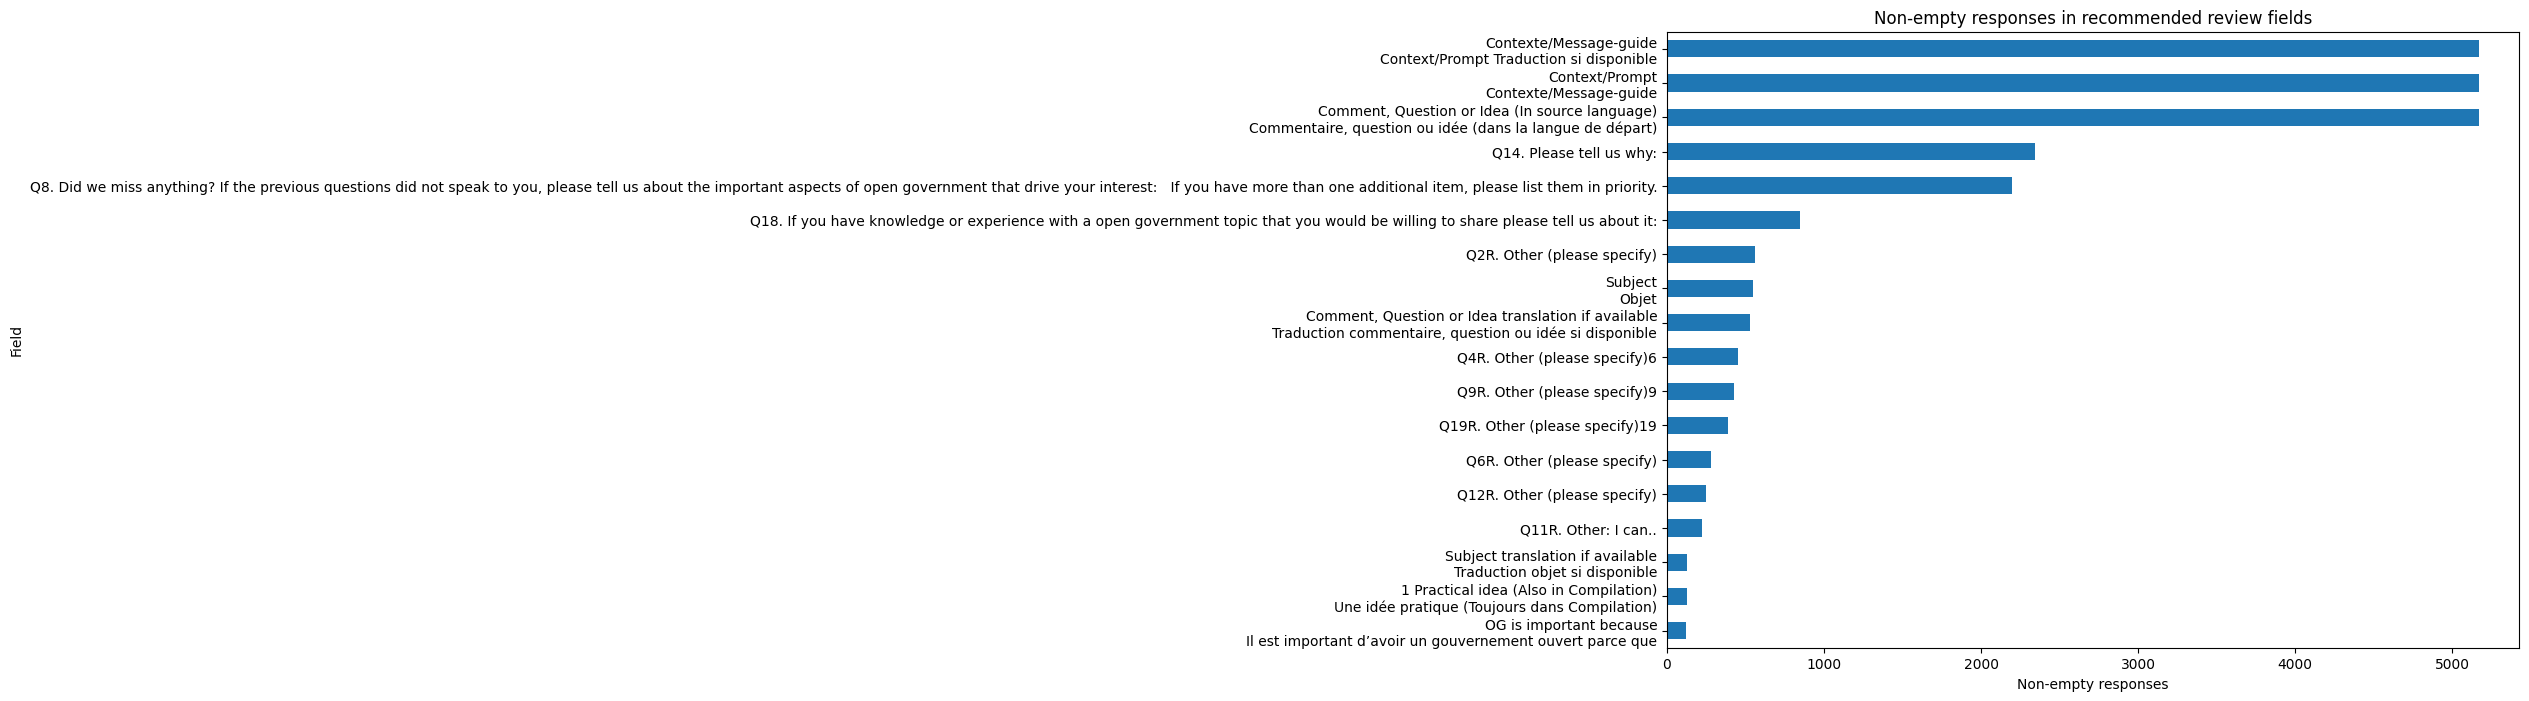

In [8]:
useful_fields = text_fields_df[
    text_fields_df["policy_relevance_recommendation"] == "review_for_policy_concerns_suggestions_or_requested_actions"
].copy()
display(useful_fields[["dataset_name", "column_name", "non_empty_responses", "avg_length", "max_length", "field_type"]])

plot_data = useful_fields.sort_values("non_empty_responses", ascending=True).tail(18)
ax = plot_data.plot.barh(x="column_name", y="non_empty_responses", legend=False, figsize=(11, 8))
ax.set_title("Non-empty responses in recommended review fields")
ax.set_xlabel("Non-empty responses")
ax.set_ylabel("Field")
plt.tight_layout()
plt.show()

In [9]:
for _, row in useful_fields.head(12).iterrows():
    print(f"\n{row['dataset_name']} :: {row['column_name']}")
    samples = json.loads(row["representative_samples_redacted"])
    for sample in samples[:3]:
        print("-", sample)


get_involved_questionnaire_2017_18 :: Q2R. Other (please specify)
- Having access to study materials and data of scientific research (published or not) funded by the Federal government
- Using gov data to shape public policy
- If I have access to the same information as the government, a lot of these other things can happen if and when I want them to. Just give me data.

get_involved_questionnaire_2017_18 :: Q4R. Other (please specify)6
- Knowing who influencers fund, and what decision-makers do on the policy areas around which they are being lobbied.
- To know that the government spending does improve Canada's position in the world.
- Understanding results of policies and programs

get_involved_questionnaire_2017_18 :: Q6R. Other (please specify)
- Having government IT tools work with all platforms, not just Microsoft or Apple
- Vote in an election with good campaign finance regulation.
- meaningful participation distinct from consultation. Onus to be accountable for how citizen and 

## 4. Identify Policy-Relevant Text

The recommended fields are candidates for later human annotation because they may contain concerns, suggestions, requested actions, or explanations. Checkbox, numeric, categorical, and metadata fields remain useful for context but are not treated as policy comments.

In [10]:
field_recommendation_summary = (
    text_fields_df.groupby(["dataset_name", "field_type", "policy_relevance_recommendation"])
    .size()
    .reset_index(name="field_count")
    .sort_values(["dataset_name", "field_count"], ascending=[True, False])
)
field_recommendation_summary

,dataset_name,field_type,policy_relevance_recommendation,field_count
3,consultation_compilation_2017_18,numeric_checkbox_or_code,do_not_treat_as_policy_comment_without_manual_review,43
0,consultation_compilation_2017_18,categorical_or_metadata,do_not_treat_as_policy_comment_without_manual_review,13
2,consultation_compilation_2017_18,free_text_candidate,review_for_policy_concerns_suggestions_or_requested_actions,6
1,consultation_compilation_2017_18,free_text_candidate,do_not_treat_as_policy_comment_without_manual_review,1
8,get_involved_questionnaire_2017_18,numeric_checkbox_or_code,do_not_treat_as_policy_comment_without_manual_review,73
7,get_involved_questionnaire_2017_18,free_text_candidate,review_for_policy_concerns_suggestions_or_requested_actions,10
5,get_involved_questionnaire_2017_18,empty_or_missing,do_not_treat_as_policy_comment_without_manual_review,8
6,get_involved_questionnaire_2017_18,free_text_candidate,do_not_treat_as_policy_comment_without_manual_review,4
9,get_involved_questionnaire_2017_18,short_text_or_metadata,do_not_treat_as_policy_comment_without_manual_review,2
4,get_involved_questionnaire_2017_18,categorical_or_metadata,do_not_treat_as_policy_comment_without_manual_review,1


## 5. Dataset Overlap Analysis

We compare schemas, ID-like columns, exact duplicate response text, and near-duplicate candidates. These are review aids only; the datasets are not merged.

In [11]:
def response_text_entries(key: str, df: pd.DataFrame, fields: pd.DataFrame) -> pd.DataFrame:
    pattern = re.compile(
        r"comment|question or idea|practical idea|public engagement question|og is important|improvements|did we miss|please tell us why|knowledge or experience|other|specify",
        re.IGNORECASE,
    )
    relevant_columns = [
        row["column_name"]
        for _, row in fields[fields["dataset_name"] == key].iterrows()
        if row["field_type"] == "free_text_candidate" and pattern.search(str(row["column_name"]))
    ]
    rows = []
    for column_name in relevant_columns:
        for index, value in df[column_name].items():
            text_key = normalized_text_key(value)
            if text_key:
                rows.append({
                    "dataset_name": key,
                    "source_row_index": int(index),
                    "source_row_number": int(index + 1),
                    "column_name": column_name,
                    "text_key": text_key,
                    "text_sample_redacted": redact_text(value),
                })
    return pd.DataFrame(rows)


all_text_entries_df = pd.concat(
    [response_text_entries(key, df, text_fields_df) for key, df in loaded_data.items()],
    ignore_index=True,
)

duplicate_text_entries_df = all_text_entries_df[
    all_text_entries_df["text_key"].duplicated(keep=False)
].sort_values(["text_key", "dataset_name", "source_row_number", "column_name"])

def schema_overlap() -> pd.DataFrame:
    rows = []
    column_sets = {key: {normalized_text_key(col) for col in df.columns} for key, df in loaded_data.items()}
    keys = list(loaded_data)
    for left_index, left_key in enumerate(keys):
        for right_key in keys[left_index + 1:]:
            common = sorted(value for value in column_sets[left_key] & column_sets[right_key] if value)
            rows.append({
                "left_dataset": left_key,
                "right_dataset": right_key,
                "left_columns": len(loaded_data[left_key].columns),
                "right_columns": len(loaded_data[right_key].columns),
                "common_normalized_columns": len(common),
                "common_column_names": json.dumps(common[:50], ensure_ascii=False),
            })
    return pd.DataFrame(rows)


def identifier_overlap() -> pd.DataFrame:
    id_values = {}
    for key, df in loaded_data.items():
        for column_name in df.columns:
            lower_name = column_name.lower()
            if lower_name in {"id", "row/ligne"} or "identifier" in lower_name or "rang" in lower_name:
                values = {str(value) for value in df[column_name].dropna() if clean_cell(value)}
                id_values[(key, column_name)] = values
    rows = []
    keys = list(id_values)
    for left_index, left in enumerate(keys):
        for right in keys[left_index + 1:]:
            common = sorted(id_values[left] & id_values[right])
            if common:
                rows.append({
                    "left_dataset": left[0],
                    "left_id_column": left[1],
                    "right_dataset": right[0],
                    "right_id_column": right[1],
                    "overlapping_ids": len(common),
                    "sample_ids": json.dumps(common[:20], ensure_ascii=False),
                })
    return pd.DataFrame(rows)


def near_duplicate_candidates(entries: pd.DataFrame, threshold=0.92, max_pairs=250) -> pd.DataFrame:
    candidates = []
    if entries.empty:
        return pd.DataFrame()
    sampled = entries[entries["text_key"].str.len().between(30, 500)].copy()
    sampled["block_key"] = sampled["text_key"].str.replace(r"[^a-z0-9]+", " ", regex=True).str.strip().str[:24]
    sampled["length_bucket"] = (sampled["text_key"].str.len() // 50).astype(int)
    sampled = sampled.sort_values(["block_key", "length_bucket", "text_key"]).head(5000)
    for _, block in sampled.groupby(["block_key", "length_bucket"], dropna=True):
        records = block.head(120).to_dict("records")
        for left_index, left in enumerate(records):
            for right in records[left_index + 1:]:
                if abs(len(left["text_key"]) - len(right["text_key"])) > 80:
                    continue
                if left["dataset_name"] == right["dataset_name"] and left["source_row_number"] == right["source_row_number"]:
                    continue
                if left["text_key"] == right["text_key"]:
                    continue
                ratio = SequenceMatcher(None, left["text_key"], right["text_key"]).ratio()
                if ratio >= threshold:
                    candidates.append({
                        "left_dataset": left["dataset_name"],
                        "left_row": left["source_row_number"],
                        "left_column": left["column_name"],
                        "right_dataset": right["dataset_name"],
                        "right_row": right["source_row_number"],
                        "right_column": right["column_name"],
                        "similarity": round(ratio, 3),
                        "left_sample_redacted": left["text_sample_redacted"],
                        "right_sample_redacted": right["text_sample_redacted"],
                    })
                    if len(candidates) >= max_pairs:
                        return pd.DataFrame(candidates)
    return pd.DataFrame(candidates)


schema_overlap_df = schema_overlap()
identifier_overlap_df = identifier_overlap()
near_duplicates_df = near_duplicate_candidates(all_text_entries_df)

display(schema_overlap_df)
display(identifier_overlap_df)
display(duplicate_text_entries_df.head(20))
display(near_duplicates_df.head(20))

,left_dataset,right_dataset,left_columns,right_columns,common_normalized_columns,common_column_names
0,get_involved_questionnaire_2017_18,individual_comments_2016_18,98,19,0,[]
1,get_involved_questionnaire_2017_18,consultation_compilation_2017_18,98,63,0,[]
2,individual_comments_2016_18,consultation_compilation_2017_18,19,63,2,"[""source"", ""source language""]"


,left_dataset,left_id_column,right_dataset,right_id_column,overlapping_ids,sample_ids
0,individual_comments_2016_18,Row\nRangée,consultation_compilation_2017_18,Row/Ligne,145,"[""1"", ""10"", ""100"", ""101"", ""102"", ""103"", ""104"", ""105"", ""106"", ""107"", ""108"", ""109"", ""11"", ""110"", ""111"", ""112"", ""113"", ""114"", ""115"", ""116""]"


,dataset_name,source_row_index,source_row_number,column_name,text_key,text_sample_redacted
12291,consultation_compilation_2017_18,3852,3853,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",#name?,#NAME?
13370,consultation_compilation_2017_18,4931,4932,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",#name?,#NAME?
2462,get_involved_questionnaire_2017_18,4528,4529,"Q8. Did we miss anything? If the previous questions did not speak to you, please tell us about the important aspects of open government ...",*****personal information removed*****,*****Personal Information Removed*****
3723,get_involved_questionnaire_2017_18,4748,4749,Q9R. Other (please specify)9,*****personal information removed*****,*****Personal Information Removed*****
3928,get_involved_questionnaire_2017_18,964,965,Q11R. Other: I can..,.,.
1579,get_involved_questionnaire_2017_18,964,965,"Q8. Did we miss anything? If the previous questions did not speak to you, please tell us about the important aspects of open government ...",.,.
2168,get_involved_questionnaire_2017_18,3525,3526,"Q8. Did we miss anything? If the previous questions did not speak to you, please tell us about the important aspects of open government ...",.,.
7649,get_involved_questionnaire_2017_18,5516,5517,Q19R. Other (please specify)19,.,.
883,get_involved_questionnaire_2017_18,5516,5517,Q4R. Other (please specify)6,.,.
1203,get_involved_questionnaire_2017_18,5516,5517,Q6R. Other (please specify),.,.


,left_dataset,left_row,left_column,right_dataset,right_row,right_column,similarity,left_sample_redacted,right_sample_redacted
0,consultation_compilation_2017_18,2564,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,2563,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.968,"15 DAYS LEFT to NOMINATE your deserving Community Leader, City Administrative Leader or City Council Leader's contributions with Open Da...","15 DAYS LEFT to NOMINATE your deserving Community Leader, City Administrative Leader or City Council Leader's contributions with Open Da..."
1,consultation_compilation_2017_18,2680,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,2682,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.921,@columgw @OpenGovCan @TBS_Canada @jaimieboyd @MelRobrt @AlexBenay @kentdaitken Awesome. Congrats!,@columgw @OpenGovCan @TBS_Canada @jaimieboyd @MelRobrt @AlexBenay @kentdaitken Welcome back!
2,consultation_compilation_2017_18,3231,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,4756,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.984,environmental impact assesments,Environmental impact assessments
3,consultation_compilation_2017_18,4406,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,4407,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.988,Financial transparency and accountability,"financial transparency and accountability,"
4,consultation_compilation_2017_18,3321,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,3322,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.928,Great message in this opengovpart article on building bipartisan buy-in to protect openness (including shout-out to #OpenGovCan!) https:...,Great message in this opengovpart article on building bipartisan buy-in to protect openness (including shout-out to #OpenGovCan!) https:...
5,consultation_compilation_2017_18,2731,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,2732,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.962,Happy I made it to #CodeAcrossTO in time to hear the challenge presentations from all theee levels of open government (@OpenGovON/@OpenG...,Happy I made it to #CodeAcrossTO in time to hear the challenge presentations from all three levels of open government (@OpenGovON/@OpenG...
6,consultation_compilation_2017_18,2723,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",consultation_compilation_2017_18,2722,"Comment, Question or Idea (In source language)\nCommentaire, question ou idée (dans la langue de départ)",0.976,Happy #OpenDataDay / #ODD18. Be sure to check out any #OpenData events in your community! @OpenGovON @Open_TO @OpenGovCan,Happy #OpenDataDay / #ODD18. Be sure to check out any #OpenData events in your community! @OpenGovON @Open_TO @OpenGovCan @open
7,get_involved_questionnaire_2017_18,4577,Q14. Please tell us why:,get_involved_questionnaire_2017_18,3652,Q14. Please tell us why:,0.970,have not been to the website yet,"have not been to the website, yet."
8,get_involved_questionnaire_2017_18,5511,Q14. Please tell us why:,get_involved_questionnaire_2017_18,3652,Q14. Please tell us why:,0.970,have 

## 6. Conservative Cleaning

The cleaned outputs keep each source separate. They add provenance columns, normalize column names in the processed copy, preserve original text values with conservative whitespace cleanup, and flag duplicate response text instead of deleting it.

In [12]:
def assign_duplicate_groups(keys: pd.Series) -> list:
    counts = Counter(key for key in keys if key is not None)
    duplicate_keys = [key for key, count in counts.items() if count > 1]
    group_for_key = {key: f"dup_{index + 1:06d}" for index, key in enumerate(duplicate_keys)}
    return [group_for_key.get(key) for key in keys]


cleaned_output_paths = []
row_count_rows = []
column_mapping_frames = []

for spec in datasets:
    key = spec.key
    original_df = loaded_data[key]
    seen = Counter()
    normalized_columns = [slugify_column(column, seen) for column in original_df.columns]
    clean_df = original_df.copy()
    clean_df.columns = normalized_columns
    clean_df.insert(0, "source_dataset", key)
    clean_df.insert(1, "source_file", spec.path.relative_to(PROJECT_ROOT).as_posix())
    clean_df.insert(2, "source_row_number", range(spec.header_rows + 1, spec.header_rows + 1 + len(clean_df)))

    # Per-row duplicate flag based on all response-like text in that row.
    row_text_keys = []
    response_columns = [
        row["column_name"]
        for _, row in text_fields_df[text_fields_df["dataset_name"] == key].iterrows()
        if row["field_type"] == "free_text_candidate"
        and re.search(
            r"comment|question or idea|practical idea|public engagement question|og is important|improvements|did we miss|please tell us why|knowledge or experience|other|specify",
            str(row["column_name"]),
            re.IGNORECASE,
        )
    ]
    for _, source_row in original_df.iterrows():
        combined = " | ".join([clean_cell(source_row.get(column)) or "" for column in response_columns]).strip()
        row_text_keys.append(normalized_text_key(combined) if combined else None)
    clean_df.insert(3, "duplicate_text_group_id", assign_duplicate_groups(pd.Series(row_text_keys)))
    clean_df.insert(4, "exclusion_reason", pd.NA)

    output_path = DATA_PROCESSED / f"{key}_source_clean.csv"
    clean_df.to_csv(output_path, index=False, encoding="utf-8", lineterminator="\n")
    cleaned_output_paths.append(output_path)

    mapping = pd.DataFrame({
        "dataset_name": key,
        "original_column_name": original_df.columns,
        "normalized_column_name": normalized_columns,
    })
    mapping_path = DATA_INTERIM / f"{key}_column_mapping.csv"
    mapping.to_csv(mapping_path, index=False, encoding="utf-8", lineterminator="\n")
    header_rows_by_dataset[key].to_csv(DATA_INTERIM / f"{key}_header_rows.csv", index=False, header=False, encoding="utf-8", lineterminator="\n")
    column_mapping_frames.append(mapping)

    row_count_rows.append({
        "dataset_name": key,
        "input_rows": len(original_df),
        "source_clean_rows": len(clean_df),
        "excluded_rows": int(clean_df["exclusion_reason"].notna().sum()),
    })

row_count_verification_df = pd.DataFrame(row_count_rows)
row_count_verification_df

,dataset_name,input_rows,source_clean_rows,excluded_rows
0,get_involved_questionnaire_2017_18,8212,8212,0
1,individual_comments_2016_18,160,160,0
2,consultation_compilation_2017_18,5169,5169,0


## 7. Audit Trail and Reports

The notebook writes machine-readable CSV summaries plus Markdown reports. These reports are regenerated from the current data each time the notebook is run.

In [13]:
inventory_df = file_metadata_df.merge(quality_summary_df, on="dataset_name", how="left")
inventory_df["source_url_or_record"] = "Local file provided by user; original source URL not documented in workspace."
inventory_df["license_provenance_status"] = "Unknown from local files; verify original open-data source/license before redistribution."
inventory_df["recommended_use"] = "Consultation audit and later human annotation for policy concerns, suggestions, or requested actions."
inventory_df["limitations"] = "Do not merge or train yet; overlap, malformed row-width anomalies, and source semantics require review."

inventory_df.to_csv(REPORTS_DIR / "data_inventory.csv", index=False, encoding="utf-8", lineterminator="\n")
text_fields_df.to_csv(DATA_INTERIM / "government_text_field_assessment.csv", index=False, encoding="utf-8", lineterminator="\n")
all_text_entries_df.to_csv(DATA_INTERIM / "government_response_text_entries.csv", index=False, encoding="utf-8", lineterminator="\n")
duplicate_text_entries_df.to_csv(DATA_INTERIM / "government_duplicate_text_entries.csv", index=False, encoding="utf-8", lineterminator="\n")
schema_overlap_df.to_csv(DATA_INTERIM / "government_schema_overlap.csv", index=False, encoding="utf-8", lineterminator="\n")
identifier_overlap_df.to_csv(DATA_INTERIM / "government_id_overlap.csv", index=False, encoding="utf-8", lineterminator="\n")
near_duplicates_df.to_csv(DATA_INTERIM / "government_near_duplicate_candidates.csv", index=False, encoding="utf-8", lineterminator="\n")
row_count_verification_df.to_csv(DATA_INTERIM / "government_row_count_verification.csv", index=False, encoding="utf-8", lineterminator="\n")

checksum_df = pd.DataFrame([
    {"dataset_name": spec.key, "relative_path": spec.path.relative_to(PROJECT_ROOT).as_posix(), "sha256": raw_checksums_before[spec.key]}
    for spec in datasets
])
checksum_df.to_csv(DATA_INTERIM / "government_raw_file_checksums.csv", index=False, encoding="utf-8", lineterminator="\n")

def markdown_table(df: pd.DataFrame) -> str:
    if df.empty:
        return "No rows produced."
    columns = list(df.columns)
    lines = ["| " + " | ".join(columns) + " |", "| " + " | ".join("---" for _ in columns) + " |"]
    for _, row in df.iterrows():
        values = [str(row[column]).replace("\n", " ") for column in columns]
        lines.append("| " + " | ".join(values) + " |")
    return "\n".join(lines)

quality_lines = [
    "# PolicyLens Data Quality Report",
    "",
    "Generated by `notebooks/01_dataset_audit_and_cleaning.ipynb`.",
    "",
    "## Confirmed Findings",
    "",
]
for _, row in inventory_df.iterrows():
    useful = useful_fields[useful_fields["dataset_name"] == row["dataset_name"]]
    quality_lines.extend([
        f"### {row['dataset_title']}",
        f"- Path: `{row['relative_path']}`",
        f"- Size: {row['file_size_bytes']} bytes; encoding: `{row['encoding']}`; delimiter: `{row['delimiter']}`",
        f"- Header: {row['header_structure']}",
        f"- Rows/columns: {row['rows']} / {row['columns']}",
        f"- Blank rows: {row['blank_rows']}; malformed row-width records: {row['malformed_records']}",
        f"- Exact duplicate rows: {row['exact_duplicate_rows']}; duplicate response-text entries: {row['duplicate_text_entries']}",
        f"- SHA-256: `{row['sha256']}`",
        f"- Clean output: `data/processed/{row['dataset_name']}_source_clean.csv`",
        f"- Recommended review fields: {len(useful)}",
        "",
    ])
    for _, field in useful.head(12).iterrows():
        quality_lines.append(f"  - `{field['column_name']}`: {field['non_empty_responses']} non-empty responses")
        for sample in json.loads(field["representative_samples_redacted"])[:2]:
            if sample:
                quality_lines.append(f"    Sample: {sample}")
    quality_lines.append("")
quality_lines.extend([
    "## Limitations",
    "",
    "- Source URLs and explicit license records are not present in this workspace.",
    "- Malformed row-width counts indicate records requiring manual CSV inspection.",
    "- Near-duplicates are heuristic review candidates, not automatic exclusions.",
    "- No model-training labels were created.",
])
(REPORTS_DIR / "data_quality_report.md").write_text("\n".join(quality_lines), encoding="utf-8")

overlap_lines = [
    "# Dataset Overlap Report",
    "",
    "Generated by `notebooks/01_dataset_audit_and_cleaning.ipynb`.",
    "",
    "## Schema Overlap",
    "",
    markdown_table(schema_overlap_df),
    "",
    "## Identifier Overlap",
    "",
    markdown_table(identifier_overlap_df) if not identifier_overlap_df.empty else "No overlapping identifier values were found among detected ID-like columns.",
    "",
    "## Exact Duplicate Response Text",
    "",
    f"Duplicate response-text rows for review: {len(duplicate_text_entries_df)}.",
    "Output: `data/interim/government_duplicate_text_entries.csv`.",
    "",
    "## Near-Duplicate Candidates",
    "",
    f"Heuristic near-duplicate candidate pairs: {len(near_duplicates_df)}.",
    "Output: `data/interim/government_near_duplicate_candidates.csv`.",
    "",
    "## Assessment",
    "",
    "The compilation dataset appears to overlap with the individual-comments dataset by row identifiers and should not be merged until source semantics and duplicate records have been reviewed.",
]
(REPORTS_DIR / "dataset_overlap_report.md").write_text("\n".join(overlap_lines), encoding="utf-8")

cleaning_log = [
    "# Cleaning Log",
    "",
    "Generated by `notebooks/01_dataset_audit_and_cleaning.ipynb`.",
    "",
    "Raw government CSV files were not modified, renamed, moved, or deleted.",
    "",
    "Transformations applied:",
    "",
    "- Located the three government consultation CSVs by filename/content hints.",
    "- Detected encoding and delimiter for each file.",
    "- Loaded the questionnaire with two header rows and preserved both header rows.",
    "- Standardized blank strings and common empty markers to null in processed copies.",
    "- Applied conservative whitespace and line-ending normalization only.",
    "- Added source dataset, source file, and source row number to cleaned outputs.",
    "- Normalized column names in processed outputs and wrote column mapping files.",
    "- Flagged duplicate response text groups; no duplicate records were deleted.",
    "",
    "Exclusions:",
    "",
    "- No rows were excluded from source-clean outputs.",
]
(REPORTS_DIR / "cleaning_log.md").write_text("\n".join(cleaning_log), encoding="utf-8")

inventory_df[["dataset_name", "rows", "columns", "exact_duplicate_rows", "duplicate_text_entries", "free_text_candidate_fields"]]

,dataset_name,rows,columns,exact_duplicate_rows,duplicate_text_entries,free_text_candidate_fields
0,get_involved_questionnaire_2017_18,8212,98,0,264,14
1,individual_comments_2016_18,160,19,13,0,9
2,consultation_compilation_2017_18,5169,63,0,34,7


## 8. Validation

These assertions are intentionally strict. If one fails, the notebook should stop so the issue can be reviewed instead of producing misleading outputs.

In [14]:
# Raw files must remain byte-for-byte unchanged.
for spec in datasets:
    assert sha256(spec.path) == raw_checksums_before[spec.key], f"Raw file changed: {spec.path}"

# Cleaned outputs must preserve row counts.
for _, row in row_count_verification_df.iterrows():
    assert int(row["input_rows"]) == int(row["source_clean_rows"]), f"Row-count mismatch for {row['dataset_name']}"
    assert int(row["excluded_rows"]) == 0, f"Unexpected exclusions for {row['dataset_name']}"

# Required audit artifacts must exist.
required_outputs = [
    REPORTS_DIR / "data_inventory.csv",
    REPORTS_DIR / "data_quality_report.md",
    REPORTS_DIR / "dataset_overlap_report.md",
    REPORTS_DIR / "cleaning_log.md",
    DATA_INTERIM / "government_raw_file_checksums.csv",
    DATA_INTERIM / "government_row_count_verification.csv",
] + cleaned_output_paths
for path in required_outputs:
    assert path.exists() and path.stat().st_size > 0, f"Missing or empty output: {path}"

print("Validation passed.")
print(f"Datasets audited: {len(datasets)}")
print(f"Cleaned outputs written: {len(cleaned_output_paths)}")

Validation passed.
Datasets audited: 3
Cleaned outputs written: 3


## Final Notebook Summary

Use `reports/data_quality_report.md` for the readable audit narrative, `reports/dataset_overlap_report.md` for overlap findings, and the CSV files in `data/interim/` for manual review of text fields, duplicates, and near-duplicates. The next research step is to manually review overlap/duplicate candidates and define an annotation guide before creating any modeling dataset.